# **Pix2Pix for Paired Rain Synthesis**

**Purpose:** Train a paired conditional GAN that receives a clean image and generates the corresponding rainy version. Because the clean and rainy images are paired, Pix2Pix is more appropriate than other GAN models.

**Pix2Pix:** Pix2Pix is a conditional Generative Adversarial Network (cGAN) designed for paired image-to-image translation. It uses a U-Net generator to transform an input image and a PatchGAN discriminator to evaluate whether local regions of the generated image appear realistic. For rain synthesis, Pix2Pix learns the mapping between corresponding clean and rainy images, allowing it to generate a rainy version of a given clean scene.


## **Step 1 - Mount Drive & Set Dataset Path**

In [2]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
from pathlib import Path

# Set Dataset Paths
CLEAN_DIR=Path('/content/drive/MyDrive/IIT Bhubaneswar B1 Projects/IIT Bhubaneswar B1 Projects/A6/did-mdn/gt')
RAIN_DIR=Path('/content/drive/MyDrive/IIT Bhubaneswar B1 Projects/IIT Bhubaneswar B1 Projects/A6/did-mdn/rainy')
assert CLEAN_DIR.exists(),f'Clean folder not found: {CLEAN_DIR}'
assert RAIN_DIR.exists(),f'Rainy folder not found: {RAIN_DIR}'
print('Clean folder:',CLEAN_DIR)
print('Rainy folder:',RAIN_DIR)

Clean folder: /content/drive/MyDrive/IIT Bhubaneswar B1 Projects/IIT Bhubaneswar B1 Projects/A6/did-mdn/gt
Rainy folder: /content/drive/MyDrive/IIT Bhubaneswar B1 Projects/IIT Bhubaneswar B1 Projects/A6/did-mdn/rainy


## **Step 2 — Pair construction and Proprocessing**
**Step 2A — Find image files**

In [4]:
def image_paths(root):
    extensions = {'.jpg', '.jpeg'}

    return sorted(
        p for p in root.rglob('*')
        if p.is_file() and p.suffix.lower() in extensions
    )

In [5]:
# Recursively return supported image files

clean_images = image_paths(CLEAN_DIR)
rainy_images = image_paths(RAIN_DIR)

print("Clean images:", len(clean_images))
print("Rainy images:", len(rainy_images))

Clean images: 1201
Rainy images: 1201


**Step 2B: matching the clean and rainy images.**

First matches relative paths without extensions; otherwise matches filename stems

In [6]:
def build_pairs(clean_dir, rainy_dir):
    clean_files = image_paths(clean_dir)
    rainy_files = image_paths(rainy_dir)

    # Create lookup for rainy images
    rainy_by_relative = {
        p.relative_to(rainy_dir).with_suffix(''): p
        for p in rainy_files
    }

    rainy_by_stem = {
        p.stem: p
        for p in rainy_files
    }

    pairs = []

    for clean_path in clean_files:
        relative_key = clean_path.relative_to(clean_dir).with_suffix('')

        if relative_key in rainy_by_relative:
            rainy_path = rainy_by_relative[relative_key]
        elif clean_path.stem in rainy_by_stem:
            rainy_path = rainy_by_stem[clean_path.stem]
        else:
            continue

        pairs.append((clean_path, rainy_path))

    return pairs

pairs = build_pairs(CLEAN_DIR, RAIN_DIR)

print("Paired images:", len(pairs))

Paired images: 1201


In [7]:
# pair construction check
for clean_path, rainy_path in pairs[:6]:
    print("Clean:", clean_path.name)
    print("Rainy:", rainy_path.name)
    print()

Clean: 0.jpg
Rainy: 0.jpg

Clean: 1.jpg
Rainy: 1.jpg

Clean: 10.jpg
Rainy: 10.jpg

Clean: 100.jpg
Rainy: 100.jpg

Clean: 1000.jpg
Rainy: 1000.jpg

Clean: 1001.jpg
Rainy: 1001.jpg



**Step 2C — Paired preprocessing**

In [8]:
from PIL import Image
import torch
from torch.utils.data import Dataset
from torchvision import transforms

class PairedRainDataset(Dataset):

    def __init__(self, pairs, train=True):
        self.pairs = pairs
        self.train = train


        self.resize = transforms.Resize((256, 256))
        self.to_tensor = transforms.ToTensor()
        self.normalize = transforms.Normalize(
            (0.5, 0.5, 0.5),
            (0.5, 0.5, 0.5)
        )

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        clean_path, rainy_path = self.pairs[index]

        # Convert both images to RGB
        clean = Image.open(clean_path).convert("RGB")
        rainy = Image.open(rainy_path).convert("RGB")

        # Resize (Both paired images have identical size)
        clean = self.resize(clean)
        rainy = self.resize(rainy)

        # Horizontal flip
        if self.train and torch.rand(1).item() < 0.5:
            clean = transforms.functional.hflip(clean)
            rainy = transforms.functional.hflip(rainy)

        # Tensor conversion
        clean = self.to_tensor(clean)
        rainy = self.to_tensor(rainy)

        # Normalization
        clean = self.normalize(clean)
        rainy = self.normalize(rainy)

        return clean, rainy

**Step 2D — PairedRainDataset constructor**

In [9]:
# Dataset length - Returns the number of matched clean/rain pairs
train_dataset = PairedRainDataset(pairs, train=True)

print("Dataset size:", len(train_dataset))

Dataset size: 1201


In [10]:
# Dataset item retrieval - Returns one clean tensor and its corresponding rainy tensor

clean, rainy = train_dataset[0]

print("Clean shape:", clean.shape)
print("Rainy shape:", rainy.shape)

print("Clean range:", clean.min().item(), "to", clean.max().item())
print("Rainy range:", rainy.min().item(), "to", rainy.max().item())

Clean shape: torch.Size([3, 256, 256])
Rainy shape: torch.Size([3, 256, 256])
Clean range: -1.0 to 1.0
Rainy range: -1.0 to 1.0


## **Step 4 — Train/Validation Split**
**Step 4A — Shuffle and split**

In [11]:
import random

# pairs are shuffled using seed 42
random.seed(42)

pairs = pairs.copy()
random.shuffle(pairs)

# Ninety percent are used for training and ten percent for validation
split_index = int(0.9 * len(pairs))

train_pairs = pairs[:split_index]
val_pairs = pairs[split_index:]

print("Training pairs:", len(train_pairs))
print("Validation pairs:", len(val_pairs))

Training pairs: 1080
Validation pairs: 121


**Step 4B — Create the two datasets**

In [12]:
train_dataset = PairedRainDataset(train_pairs, train=True)
val_dataset = PairedRainDataset(val_pairs, train=False)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))

Training dataset: 1080
Validation dataset: 121


**Step 4C — Create DataLoaders for batch processing**

In [13]:
from torch.utils.data import DataLoader

# The training batch size is 4
train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

# The validation batch size is 1
val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 270
Validation batches: 121


## **Step 5 — Generator U-Net**



In [14]:
import torch.nn as nn

class Generator(nn.Module):

    def __init__(self):
        super().__init__()

        # Encoder
        self.down1 = nn.Conv2d(3, 64, 4, 2, 1)

        self.down2 = nn.Sequential(
            nn.Conv2d(64, 128, 4, 2, 1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True)
        )

        self.down3 = nn.Sequential(
            nn.Conv2d(128, 256, 4, 2, 1),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True)
        )

        self.down4 = nn.Sequential(
            nn.Conv2d(256, 512, 4, 2, 1),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True)
        )

        self.down5 = nn.Sequential(
            nn.Conv2d(512, 512, 4, 2, 1),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True)
        )

        self.down6 = nn.Sequential(
            nn.Conv2d(512, 512, 4, 2, 1),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True)
        )

        self.down7 = nn.Sequential(
            nn.Conv2d(512, 512, 4, 2, 1),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True)
        )

        # Bottleneck
        self.bottleneck = nn.Sequential(
            nn.Conv2d(512, 512, 4, 2, 1),
            nn.ReLU(inplace=True)
        )

        # Decoder
        self.up1 = nn.Sequential(
            nn.ConvTranspose2d(512, 512, 4, 2, 1),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5)
        )

        self.up2 = nn.Sequential(
            nn.ConvTranspose2d(1024, 512, 4, 2, 1),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5)
        )

        self.up3 = nn.Sequential(
            nn.ConvTranspose2d(1024, 512, 4, 2, 1),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5)
        )

        self.up4 = nn.Sequential(
            nn.ConvTranspose2d(1024, 512, 4, 2, 1),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True)
        )

        self.up5 = nn.Sequential(
            nn.ConvTranspose2d(1024, 256, 4, 2, 1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )

        self.up6 = nn.Sequential(
            nn.ConvTranspose2d(512, 128, 4, 2, 1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True)
        )

        self.up7 = nn.Sequential(
            nn.ConvTranspose2d(256, 64, 4, 2, 1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )

        # Output
        self.output = nn.Sequential(
            nn.ConvTranspose2d(128, 3, 4, 2, 1),
            nn.Tanh()
        )

    def forward(self, x):

        # Encoder
        d1 = self.down1(x)
        d1 = nn.functional.leaky_relu(d1, 0.2)

        d2 = self.down2(d1)
        d3 = self.down3(d2)
        d4 = self.down4(d3)
        d5 = self.down5(d4)
        d6 = self.down6(d5)
        d7 = self.down7(d6)

        # Bottleneck
        b = self.bottleneck(d7)

        # Decoder with skip connections
        u1 = self.up1(b)
        u1 = torch.cat([u1, d7], dim=1)

        u2 = self.up2(u1)
        u2 = torch.cat([u2, d6], dim=1)

        u3 = self.up3(u2)
        u3 = torch.cat([u3, d5], dim=1)

        u4 = self.up4(u3)
        u4 = torch.cat([u4, d4], dim=1)

        u5 = self.up5(u4)
        u5 = torch.cat([u5, d3], dim=1)

        u6 = self.up6(u5)
        u6 = torch.cat([u6, d2], dim=1)

        u7 = self.up7(u6)
        u7 = torch.cat([u7, d1], dim=1)

        return self.output(u7)

In [15]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

G = Generator().to(device)

print(G)

Generator(
  (down1): Conv2d(3, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (down2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.2, inplace=True)
  )
  (down3): Sequential(
    (0): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.2, inplace=True)
  )
  (down4): Sequential(
    (0): Conv2d(256, 512, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.2, inplace=True)
  )
  (down5): Sequential(
    (0): Conv2d(512, 512, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_run

In [16]:
clean_batch, rainy_batch = next(iter(train_loader))

clean_batch = clean_batch.to(device)

fake_rain = G(clean_batch)

print("Input shape:", clean_batch.shape)
print("Output shape:", fake_rain.shape)

Input shape: torch.Size([4, 3, 256, 256])
Output shape: torch.Size([4, 3, 256, 256])


## **Step 6 — Conditional PatchGAN Discriminator**

In [17]:
class Discriminator(nn.Module):

    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            # Stage 1: 6 -> 64
            nn.Conv2d(6, 64, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),

            # Stage 2: 64 -> 128
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            # Stage 3: 128 -> 256
            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            # Stage 4: 256 -> 512
            nn.Conv2d(256, 512, kernel_size=4, stride=1, padding=1),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),

            # Final PatchGAN output
            nn.Conv2d(512, 1, kernel_size=4, stride=1, padding=1)
        )

    def forward(self, clean, image):
        x = torch.cat([clean, image], dim=1)
        return self.model(x)

In [18]:
D = Discriminator().to(device)

prediction = D(clean_batch, fake_rain)

print("Discriminator output shape:", prediction.shape)

Discriminator output shape: torch.Size([4, 1, 30, 30])


## **Step 7 — Weight Initialization**
The initialization function accepts one layer/module. Convolution and transposed-convolution weights use a normal distribution with mean 0 and standard deviation 0.02. Their biases are set to zero. Batch-normalization weights use mean 1 and standard deviation 0.02, and their biases are zero.


In [19]:
def weights_init(m):

    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)

        if m.bias is not None:
            nn.init.constant_(m.bias, 0)

    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.constant_(m.bias, 0)

In [20]:
G.apply(weights_init)
D.apply(weights_init)

print("Weights initialized.")

Weights initialized.


## **Step 8 — Loss Functions and Optimizers**

In [21]:
criterion_GAN = nn.BCEWithLogitsLoss()
criterion_L1 = nn.L1Loss()

LAMBDA_L1 = 100

optimizer_G = torch.optim.Adam(
    G.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

optimizer_D = torch.optim.Adam(
    D.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

print("Loss functions and optimizers are ready.")

Loss functions and optimizers are ready.


## **Step 9 — Set up the training loop**

In [23]:
# Set epochs

EPOCHS = 50
print("Epochs:", EPOCHS)

Epochs: 50


## **Step 10 - Training Loop**

In [25]:
# we will create a small list to store the losses
G_losses = []
D_losses = []

# training loop
for epoch in range(EPOCHS):

    G.train()
    D.train()

    epoch_G_loss = 0.0
    epoch_D_loss = 0.0

    for clean, real_rain in train_loader:

        clean = clean.to(device)
        real_rain = real_rain.to(device)


        # 1. Generate fake rainy image
        fake_rain = G(clean)


        # 2. Train Discriminator
        optimizer_D.zero_grad()

        real_pred = D(clean, real_rain)
        fake_pred = D(clean, fake_rain.detach())

        real_labels = torch.ones_like(real_pred)
        fake_labels = torch.zeros_like(fake_pred)

        loss_D_real = criterion_GAN(real_pred, real_labels)
        loss_D_fake = criterion_GAN(fake_pred, fake_labels)

        loss_D = (loss_D_real + loss_D_fake) / 2

        loss_D.backward()
        optimizer_D.step()

        # 3. Train Generator
        optimizer_G.zero_grad()

        fake_pred = D(clean, fake_rain)

        loss_G_GAN = criterion_GAN(
            fake_pred,
            torch.ones_like(fake_pred)
        )

        loss_G_L1 = criterion_L1(fake_rain, real_rain)

        loss_G = loss_G_GAN + LAMBDA_L1 * loss_G_L1

        loss_G.backward()
        optimizer_G.step()

        # 4. Record losses
        epoch_G_loss += loss_G.item()
        epoch_D_loss += loss_D.item()

    # Average losses for the epoch
    epoch_G_loss /= len(train_loader)
    epoch_D_loss /= len(train_loader)

    G_losses.append(epoch_G_loss)
    D_losses.append(epoch_D_loss)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"G Loss: {epoch_G_loss:.4f} "
        f"D Loss: {epoch_D_loss:.4f}"
    )

Epoch [1/50] G Loss: 14.7132 D Loss: 0.6420
Epoch [2/50] G Loss: 13.4272 D Loss: 0.5310
Epoch [3/50] G Loss: 13.3530 D Loss: 0.5663
Epoch [4/50] G Loss: 13.2591 D Loss: 0.5827
Epoch [5/50] G Loss: 13.2909 D Loss: 0.5879
Epoch [6/50] G Loss: 13.2754 D Loss: 0.5606
Epoch [7/50] G Loss: 13.2714 D Loss: 0.5881
Epoch [8/50] G Loss: 13.1855 D Loss: 0.5896
Epoch [9/50] G Loss: 13.2564 D Loss: 0.5778
Epoch [10/50] G Loss: 13.3072 D Loss: 0.5668
Epoch [11/50] G Loss: 13.2079 D Loss: 0.5873
Epoch [12/50] G Loss: 13.2450 D Loss: 0.5872
Epoch [13/50] G Loss: 13.2386 D Loss: 0.5787
Epoch [14/50] G Loss: 13.2499 D Loss: 0.5830
Epoch [15/50] G Loss: 13.2482 D Loss: 0.5782
Epoch [16/50] G Loss: 13.3226 D Loss: 0.5764
Epoch [17/50] G Loss: 13.3867 D Loss: 0.5544
Epoch [18/50] G Loss: 13.4157 D Loss: 0.5446
Epoch [19/50] G Loss: 13.5203 D Loss: 0.5332
Epoch [20/50] G Loss: 13.8284 D Loss: 0.4707
Epoch [21/50] G Loss: 13.5451 D Loss: 0.5140
Epoch [22/50] G Loss: 13.6713 D Loss: 0.4922
Epoch [23/50] G Los

## **Step 11 — Save the trained model**

In [26]:
checkpoint = {
    "epoch": EPOCHS,
    "G_state_dict": G.state_dict(),
    "D_state_dict": D.state_dict(),
    "optimizer_G_state_dict": optimizer_G.state_dict(),
    "optimizer_D_state_dict": optimizer_D.state_dict()
}

torch.save(checkpoint, "latest.pt")

print("Saved latest.pt")

Saved latest.pt


## **Step 12 — Validation Results**
Validation previews follow clean → generated rain → real rain.

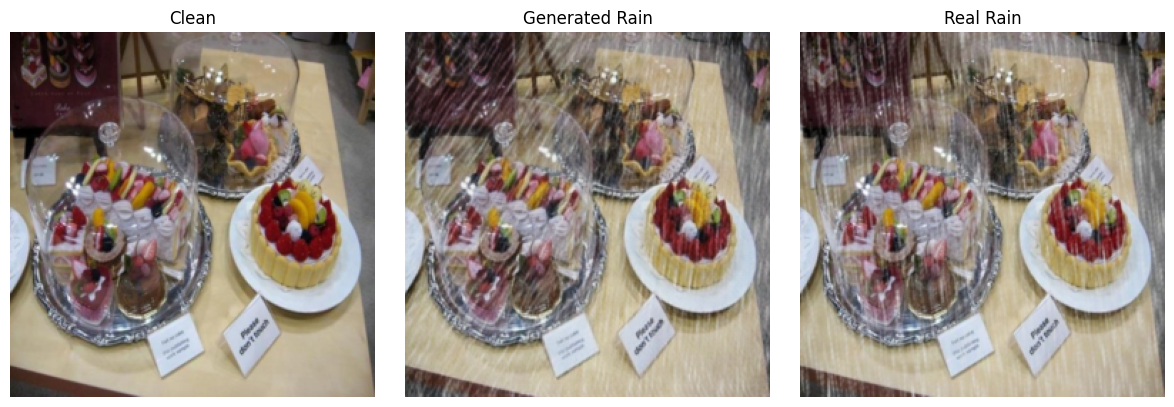

In [27]:
import matplotlib.pyplot as plt

G.eval()

clean, real_rain = next(iter(val_loader))

clean = clean.to(device)

with torch.no_grad():
    fake_rain = G(clean)

def denormalize(x):
    return x * 0.5 + 0.5

clean = denormalize(clean.cpu()).clamp(0, 1)
fake_rain = denormalize(fake_rain.cpu()).clamp(0, 1)
real_rain = denormalize(real_rain).clamp(0, 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(clean[0].permute(1, 2, 0))
plt.title("Clean")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(fake_rain[0].permute(1, 2, 0))
plt.title("Generated Rain")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(real_rain[0].permute(1, 2, 0))
plt.title("Real Rain")
plt.axis("off")

plt.tight_layout()
plt.show()

## **Step 13 — Save validation image**

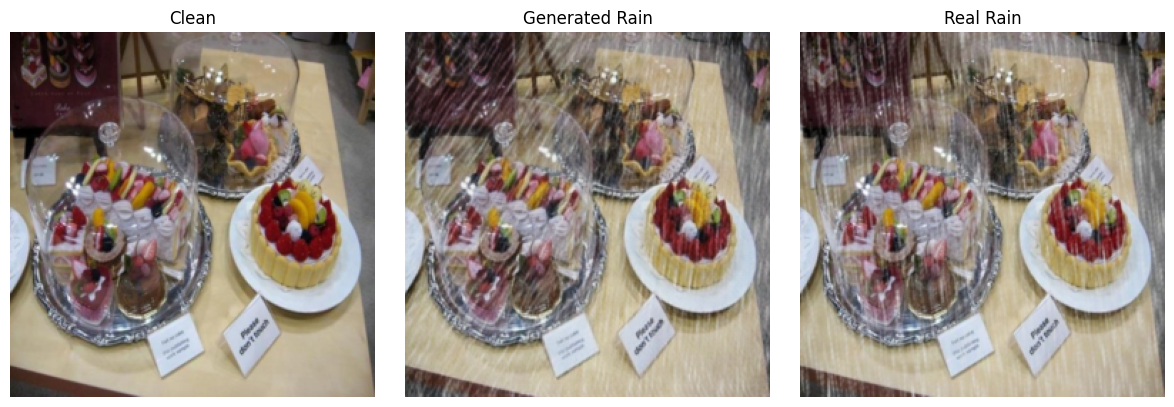

Saved validation_result.png


In [28]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(clean[0].permute(1, 2, 0))
plt.title("Clean")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(fake_rain[0].permute(1, 2, 0))
plt.title("Generated Rain")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(real_rain[0].permute(1, 2, 0))
plt.title("Real Rain")
plt.axis("off")

plt.tight_layout()
plt.savefig("validation_result.png", dpi=150, bbox_inches="tight")
plt.show()

print("Saved validation_result.png")

## **Step 14 — Final inference and ZIP export**

In [29]:
from pathlib import Path
from PIL import Image
import zipfile
import torch

G.eval()

output_dir = Path("synthetic_rain")
output_dir.mkdir(exist_ok=True)

with torch.no_grad():

    for i, (clean, _) in enumerate(val_loader):

        clean = clean.to(device)

        fake_rain = G(clean)

        fake_rain = fake_rain * 0.5 + 0.5
        fake_rain = fake_rain.clamp(0, 1)

        image = fake_rain[0].cpu()
        image = image.permute(1, 2, 0).numpy()
        image = (image * 255).astype("uint8")

        output_path = output_dir / f"{i}_synthetic_rain.png"

        Image.fromarray(image).save(output_path)

print("Generated images:", len(list(output_dir.glob("*.png"))))

Generated images: 121


In [30]:
import zipfile
from pathlib import Path

output_dir = Path("synthetic_rain")
zip_path = Path("synthetic_rain.zip")

image_files = sorted(output_dir.glob("*.png"))

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zip_file:
    for image_path in image_files:
        zip_file.write(image_path, arcname=image_path.name)

print("Created:", zip_path)
print("Images in ZIP:", len(image_files))

Created: synthetic_rain.zip
Images in ZIP: 121
